# Part 3: Economic Populism Premium

Asks: **do Democrats pay a penalty in economically distressed counties, and has that penalty grown over time?**

Methodology:
1. Pull county-level economic characteristics from Census ACS 2020 5-year estimates
2. Regress 2020→2024 swing on income, education, and racial composition (WLS, weighted by 2020 turnout)
3. Compare Democratic share *relative to Obama 2012* across election cycles, stratified by income quartile — this is the "populism premium" trend line

**Populism premium** = the extra votes a candidate gains (or loses) in economically distressed areas relative to an economically comfortable baseline, holding other things equal.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import requests
from pathlib import Path
from dotenv import load_dotenv
import warnings
warnings.filterwarnings('ignore')

load_dotenv('../.env')
CENSUS_API_KEY = os.getenv('CENSUS_API_KEY')

if not CENSUS_API_KEY or CENSUS_API_KEY == 'your_census_key_here':
    raise ValueError(
        'CENSUS_API_KEY not set. Get a free key at https://api.census.gov/data/key_signup.html '
        'and add it to your .env file as CENSUS_API_KEY=your_key'
    )

DATA_DIR    = Path('../data/raw/mit_election_lab')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')

for d in [PROC_DIR, FIGURES_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

## 1. Pull county-level economic data from Census ACS 2020

In [2]:
def pull_acs_county(year=2020, api_key=None):
    """Pull key economic + demographic variables from ACS 5-year estimates."""
    variables = [
        'NAME',
        'B19013_001E',   # median household income
        'B15003_001E',   # population 25+ (education denominator)
        'B15003_022E',   # bachelor's degree
        'B15003_023E',   # master's degree
        'B15003_024E',   # professional school degree
        'B15003_025E',   # doctorate degree
        'B03002_003E',   # white non-Hispanic
        'B03002_001E',   # total population for race denominator
        'B01003_001E',   # total population
        'B23025_005E',   # unemployed in labor force
        'B23025_002E',   # total in labor force
    ]
    params = {'get': ','.join(variables), 'for': 'county:*', 'in': 'state:*'}
    if api_key:
        params['key'] = api_key

    url = f'https://api.census.gov/data/{year}/acs/acs5'
    print(f'Pulling ACS {year} 5-year county data...', end=' ', flush=True)
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()
    df = pd.DataFrame(data[1:], columns=data[0])

    df['county_fips'] = (df['state'].str.zfill(2) + df['county'].str.zfill(3)).astype(int)

    for col in df.columns:
        if col not in ('NAME', 'state', 'county'):
            df[col] = pd.to_numeric(df[col], errors='coerce')

    college = df[['B15003_022E','B15003_023E','B15003_024E','B15003_025E']].sum(axis=1)
    df['college_share']   = college / df['B15003_001E']
    df['white_nh_share']  = df['B03002_003E'] / df['B03002_001E']
    df['unemp_rate']      = df['B23025_005E'] / df['B23025_002E']
    df['med_income']      = df['B19013_001E']
    df['population']      = df['B01003_001E']
    df['white_nocollege'] = df['white_nh_share'] * (1 - df['college_share'])

    df = df[df['med_income'] > 0].copy()
    print(f'OK ({len(df)} counties)')
    return df[['county_fips','med_income','college_share','white_nh_share',
               'white_nocollege','unemp_rate','population']].copy()

acs = pull_acs_county(2020, api_key=CENSUS_API_KEY)
acs.describe().round(3)

Pulling ACS 2020 5-year county data... OK (3220 counties)


,county_fips,med_income,college_share,white_nh_share,white_nocollege,unemp_rate,population
count,3220.000,3220.000,3220.000,3220.000,3220.000,3220.000,3.220000e+03
mean,31379.203,54171.515,0.226,0.739,0.572,0.054,1.024294e+05
std,16297.676,15482.259,0.096,0.230,0.195,0.032,3.283096e+05
min,1001.000,12283.000,0.000,0.000,0.000,0.000,1.170000e+02
25%,19030.500,44939.000,0.160,0.623,0.463,0.036,1.113400e+04
50%,30022.000,52381.000,0.203,0.824,0.611,0.049,2.600150e+04
75%,46103.500,61241.750,0.267,0.919,0.724,0.064,6.697425e+04
max,72153.000,147111.000,0.791,1.000,1.000,0.348,1.004068e+07


## 2. Merge economic data with county vote decomposition

In [3]:
cty = pd.read_csv(PROC_DIR / 'county_decomposition.csv')
df = cty.merge(acs, on='county_fips', how='inner')
df['log_income'] = np.log(df['med_income'])

print(f'County decomposition:   {len(cty):,}')
print(f'After ACS merge:        {len(df):,}')
print(f'Coverage (by 2020 votes): '
      f'{df["total_votes_2020"].sum()/cty["total_votes_2020"].sum():.1%}')
df[['med_income','college_share','white_nh_share','unemp_rate','swing_2024']].describe().round(3)

County decomposition:   3,111
After ACS merge:        3,110
Coverage (by 2020 votes): 100.0%


,med_income,college_share,white_nh_share,unemp_rate,swing_2024
count,3110.000,3110.000,3110.000,3110.000,3110.000
mean,54897.658,0.226,0.761,0.051,-3.473
std,14605.933,0.097,0.199,0.025,3.269
min,22292.000,0.000,0.010,0.000,-27.950
25%,45579.000,0.159,0.644,0.036,-5.068
50%,52713.000,0.202,0.833,0.048,-3.148
75%,61333.250,0.267,0.920,0.062,-1.464
max,147111.000,0.791,1.000,0.304,9.219


## 3. Regression: what economic variables predict the 2020→2024 swing?

WLS weighted by 2020 county turnout so large counties drive the coefficients proportionally.

In [4]:
# Partial out prior partisan lean (dem_share_2020) to isolate economic signal
formula = ('swing_2024 ~ log_income + college_share + white_nocollege '
           '+ unemp_rate + dem_share_2020')

model = smf.wls(formula, data=df, weights=df['total_votes_2020']).fit()
print(model.summary())

                            WLS Regression Results                            
Dep. Variable:             swing_2024   R-squared:                       0.418
Model:                            WLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                     445.4
Date:                Thu, 17 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:37:35   Log-Likelihood:                -10122.
No. Observations:                3110   AIC:                         2.026e+04
Df Residuals:                    3104   BIC:                         2.029e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          21.8645      4.200     

In [5]:
# Marginal effects at mean — easier to interpret
coef = model.params
print('Key marginal effects (holding other vars at mean):')
print(f'  +$10K income (log scale):       {coef["log_income"] * np.log(1+10000/df["med_income"].mean()):+.2f} pp swing')
print(f'  +10pp college share:            {coef["college_share"] * 0.10:+.2f} pp swing')
print(f'  +10pp white non-college share:  {coef["white_nocollege"] * 0.10:+.2f} pp swing')
print(f'  +1pp unemployment rate:         {coef["unemp_rate"] * 0.01:+.2f} pp swing')

Key marginal effects (holding other vars at mean):
  +$10K income (log scale):       -0.58 pp swing
  +10pp college share:            +2.05 pp swing
  +10pp white non-college share:  +1.64 pp swing
  +1pp unemployment rate:         -0.30 pp swing


## 4. Swing by economic quartile — 2020→2024

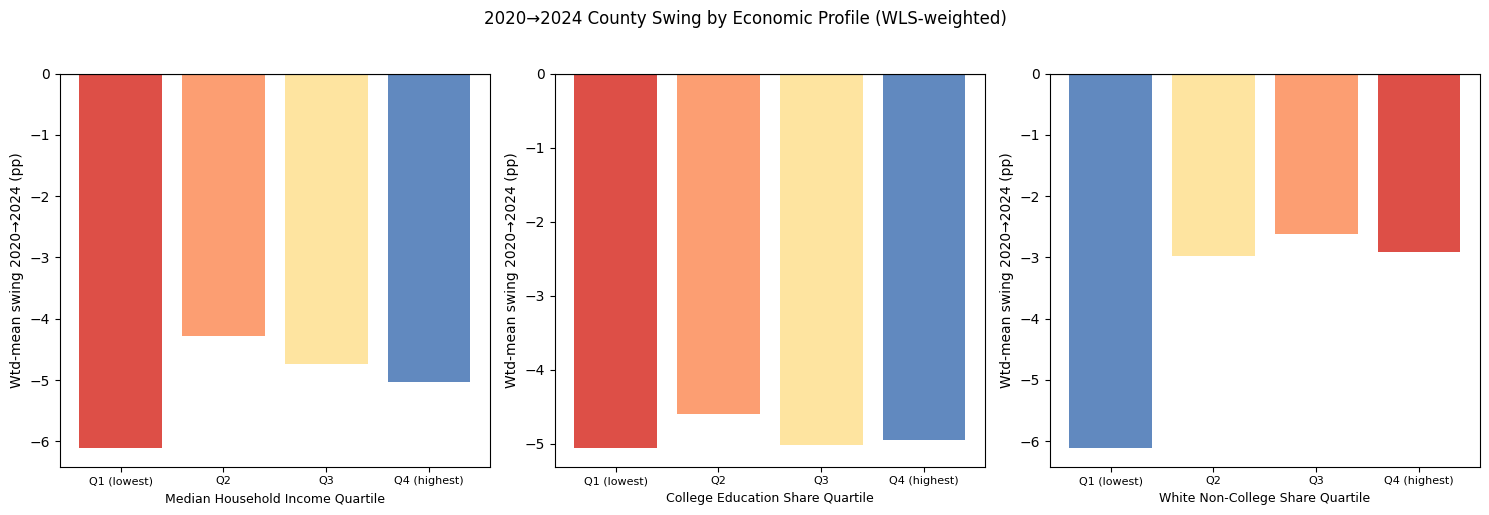

Saved: outputs/figures/populism_premium_2024.png


In [6]:
df['income_q']  = pd.qcut(df['med_income'],   4, labels=['Q1 (lowest)','Q2','Q3','Q4 (highest)'])
df['college_q'] = pd.qcut(df['college_share'], 4, labels=['Q1 (lowest)','Q2','Q3','Q4 (highest)'])
df['wnc_q']     = pd.qcut(df['white_nocollege'], 4, labels=['Q1 (lowest)','Q2','Q3','Q4 (highest)'])

def wtd_mean(grp, col, wt='total_votes_2020'):
    return np.average(grp[col], weights=grp[wt])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
palette = ['#d73027','#fc8d59','#fee090','#4575b4']

for ax, q_col, title in [
    (axes[0], 'income_q',  'Median Household Income Quartile'),
    (axes[1], 'college_q', 'College Education Share Quartile'),
    (axes[2], 'wnc_q',     'White Non-College Share Quartile'),
]:
    means = df.groupby(q_col).apply(lambda g: wtd_mean(g, 'swing_2024')).reset_index(name='swing')
    # Reverse palette for wnc so high wnc = red
    pal = palette[::-1] if q_col == 'wnc_q' else palette
    ax.bar(means[q_col].astype(str), means['swing'], color=pal, alpha=0.85)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xlabel(title, fontsize=9)
    ax.set_ylabel('Wtd-mean swing 2020→2024 (pp)')
    ax.tick_params(axis='x', labelsize=8)

plt.suptitle('2020→2024 County Swing by Economic Profile (WLS-weighted)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'populism_premium_2024.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/populism_premium_2024.png')

## 5. Multi-cycle comparison: Obama 2012 baseline

Compare each Democrat's county-level share relative to Obama 2012, stratified by income quartile. This isolates the **change in the income gradient** across cycles — the core "populism premium" trend.

In [7]:
elections = pd.read_csv(DATA_DIR / 'county_returns.csv')
elections = elections[elections['state'] != 'ALASKA']   # district-level, redistricted 2022 — see notebook 03

# Wide format: one row per county, dem_share by year
frames = {}
for yr in [2012, 2016, 2020, 2024]:
    sub = elections[elections['year'] == yr][['state','county_fips','dem_share','total_votes']].copy()
    sub = sub.rename(columns={'dem_share': f'dem_share_{yr}', 'total_votes': f'total_{yr}'})
    frames[yr] = sub

wide = frames[2012]
for yr in [2016, 2020, 2024]:
    wide = wide.merge(frames[yr], on=['state','county_fips'], how='inner')

wide = wide.merge(acs[['county_fips','med_income','population']], on='county_fips', how='inner')

# Swing relative to Obama 2012
wide['swing_2016'] = (wide['dem_share_2016'] - wide['dem_share_2012']) * 100
wide['swing_2020'] = (wide['dem_share_2020'] - wide['dem_share_2012']) * 100
wide['swing_2024'] = (wide['dem_share_2024'] - wide['dem_share_2012']) * 100

wide['income_q'] = pd.qcut(wide['med_income'], 4,
                            labels=['Q1\n(lowest)','Q2','Q3','Q4\n(highest)'])

print(f'Counties with complete 2012–2024 data: {len(wide):,}')

Counties with complete 2012–2024 data: 3,110


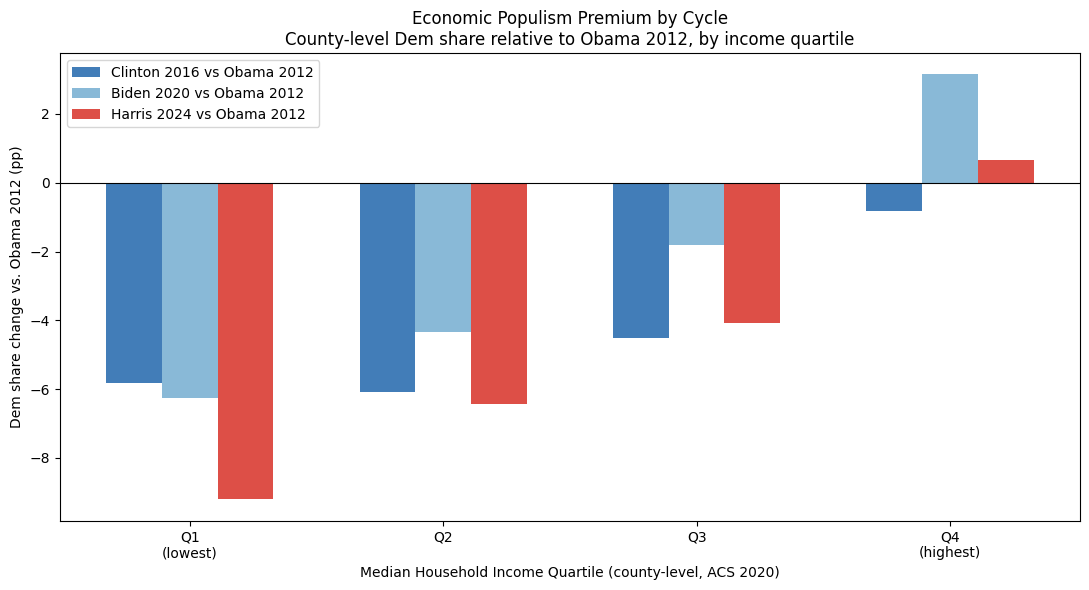

Saved: outputs/figures/populism_premium_cycles.png


In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(4)
w = 0.22

cycles = [
    ('swing_2016', 'Clinton 2016 vs Obama 2012', '#2166ac', 'total_2016'),
    ('swing_2020', 'Biden 2020 vs Obama 2012',   '#74add1', 'total_2020'),
    ('swing_2024', 'Harris 2024 vs Obama 2012',  '#d73027', 'total_2024'),
]

for i, (col, label, color, wt_col) in enumerate(cycles):
    means = wide.groupby('income_q').apply(
        lambda g: np.average(g[col], weights=g[wt_col])
    ).values
    bars = ax.bar(x + (i - 1) * w, means, width=w, label=label, color=color, alpha=0.85)

ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(['Q1\n(lowest)','Q2','Q3','Q4\n(highest)'])
ax.set_xlabel('Median Household Income Quartile (county-level, ACS 2020)')
ax.set_ylabel('Dem share change vs. Obama 2012 (pp)')
ax.set_title('Economic Populism Premium by Cycle\n'
             'County-level Dem share relative to Obama 2012, by income quartile', fontsize=12)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'populism_premium_cycles.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: outputs/figures/populism_premium_cycles.png')

In [9]:
# Quantify: the income gradient slope (Q4 minus Q1) by cycle
print('Income gradient (Q4 richest minus Q1 poorest, pp vs. Obama 2012):')
print('Positive = richer counties swung more toward Dem (or less toward R)')
print('Negative = poorer counties swung more toward R')
print()
for col, label, wt_col in [
    ('swing_2016', 'Clinton 2016', 'total_2016'),
    ('swing_2020', 'Biden 2020',   'total_2020'),
    ('swing_2024', 'Harris 2024',  'total_2024'),
]:
    q_means = wide.groupby('income_q').apply(
        lambda g: np.average(g[col], weights=g[wt_col])
    )
    grad = q_means.iloc[-1] - q_means.iloc[0]
    print(f'  {label:16s}  Q1={q_means.iloc[0]:+.1f}  Q2={q_means.iloc[1]:+.1f}  '
          f'Q3={q_means.iloc[2]:+.1f}  Q4={q_means.iloc[3]:+.1f}  gradient={grad:+.1f} pp')

Income gradient (Q4 richest minus Q1 poorest, pp vs. Obama 2012):
Positive = richer counties swung more toward Dem (or less toward R)
Negative = poorer counties swung more toward R

  Clinton 2016      Q1=-5.8  Q2=-6.1  Q3=-4.5  Q4=-0.8  gradient=+5.0 pp
  Biden 2020        Q1=-6.3  Q2=-4.3  Q3=-1.8  Q4=+3.1  gradient=+9.4 pp
  Harris 2024       Q1=-9.2  Q2=-6.4  Q3=-4.1  Q4=+0.7  gradient=+9.9 pp


## 6. Save outputs

In [10]:
# County profile with economic variables
df[[
    'state','county_fips','med_income','college_share',
    'white_nh_share','white_nocollege','unemp_rate','population',
    'dem_share_2020','dem_share_2024','swing_2024','swing_2020',
    'delta_dem','turnout_component','share_component',
]].to_csv(PROC_DIR / 'county_economic_profile.csv', index=False)

# Multi-cycle comparison
wide[[
    'state','county_fips','med_income',
    'dem_share_2012','dem_share_2016','dem_share_2020','dem_share_2024',
    'swing_2016','swing_2020','swing_2024',
]].to_csv(TABLES_DIR / 'county_multiyear_swing.csv', index=False)

# Regression coefficients
pd.DataFrame({
    'coef':    model.params.round(4),
    'std_err': model.bse.round(4),
    't':       model.tvalues.round(3),
    'p':       model.pvalues.round(4),
}).to_csv(TABLES_DIR / 'populism_regression_coefs.csv')

print('Saved:')
print('  data/processed/county_economic_profile.csv')
print('  outputs/tables/county_multiyear_swing.csv')
print('  outputs/tables/populism_regression_coefs.csv')

Saved:
  data/processed/county_economic_profile.csv
  outputs/tables/county_multiyear_swing.csv
  outputs/tables/populism_regression_coefs.csv
